# DATA 266 Lab 2 — Part 3

This notebook runs the local multi-agent pipeline, evaluates the committed scenarios and red-team cases, and tests generation with the selected Part 2 LoRA adapter.

Run the cells from top to bottom on the GPU lab machine.

In [1]:
import json
import os
import random
import subprocess
import sys
from pathlib import Path

import numpy as np
import torch

SEED = 266
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Find the project root regardless of whether Jupyter opened the root,
# part3, or part3/notebooks as its working directory.
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next(
    (
        path for path in candidates
        if (path / 'part3' / 'src').exists()
        and (path / 'docs' / 'part3_cases.json').exists()
    ),
    None,
)
if ROOT is None:
    raise FileNotFoundError(
        'Could not locate the lab2_solution project root. Open this notebook inside the extracted project.'
    )

SRC_DIR = ROOT / 'part3' / 'src'
OUT_DIR = ROOT / 'part3' / 'outputs'
OUT_DIR.mkdir(parents=True, exist_ok=True)
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

commit = subprocess.run(
    ['git', 'rev-parse', '--short', 'HEAD'],
    cwd=ROOT,
    capture_output=True,
    text=True,
).stdout.strip() or 'not-a-git-checkout'

print({
    'project_root': str(ROOT),
    'python': sys.version.split()[0],
    'torch': torch.__version__,
    'gpu': torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'cpu',
    'cuda_available': torch.cuda.is_available(),
    'seed': SEED,
    'commit': commit,
})

{'project_root': 'C:\\Users\\saketh1\\Desktop\\lab2_solution', 'python': '3.13.2', 'torch': '2.15.0+cu132', 'gpu': 'NVIDIA GeForce RTX 4090', 'cuda_available': True, 'seed': 266, 'commit': 'not-a-git-checkout'}


## Configuration

The notebook uses the rank-16 adapter by default. Set `PART3_LORA_RANK` to `4` if the rank-4 adapter produced better images. The adapter path is configured here before the agent module is used, so `ROOT` is always defined.

In [2]:
SELECTED_RANK = int(os.environ.get('PART3_LORA_RANK', '16'))
ADAPTER_DIR = ROOT / 'part2' / 'outputs' / f'lora_rank{SELECTED_RANK}'
if not ADAPTER_DIR.exists():
    raise FileNotFoundError(
        f'Part 2 adapter was not found: {ADAPTER_DIR}. Run Part 2 first or change PART3_LORA_RANK.'
    )

os.environ['PART2_ADAPTER_PATH'] = str(ADAPTER_DIR)
os.environ['PART3_OUTPUT_DIR'] = str(OUT_DIR)
os.environ.setdefault('RUN_PART3_EVAL', '1')
RUN_GENERATION_TEST = os.environ.get('RUN_PART3_GENERATION', '1') == '1'

adapter_files = [
    {'name': path.name, 'bytes': path.stat().st_size}
    for path in sorted(ADAPTER_DIR.iterdir())
    if path.is_file()
]
print({
    'selected_rank': SELECTED_RANK,
    'adapter_dir': str(ADAPTER_DIR),
    'adapter_files': adapter_files,
    'run_evaluation': os.environ.get('RUN_PART3_EVAL'),
    'run_generation_test': RUN_GENERATION_TEST,
})

{'selected_rank': 16, 'adapter_dir': 'C:\\Users\\saketh1\\Desktop\\lab2_solution\\part2\\outputs\\lora_rank16', 'adapter_files': [{'name': 'pytorch_lora_weights.safetensors', 'bytes': 12792952}, {'name': 'training_record.json', 'bytes': 364}], 'run_evaluation': '1', 'run_generation_test': True}


In [3]:
from agents import run
from evaluate import run_evaluation

print('Part 3 modules imported successfully.')

Part 3 modules imported successfully.


## Basic pipeline smoke test

This checks the planner, vision fallback, typed state, and trace creation. It does not require an input image.

In [4]:
smoke_state = run('caption this image', out=OUT_DIR)
print({
    'route': smoke_state.route,
    'vision': smoke_state.vision,
    'error': smoke_state.error,
    'trace_steps': len(smoke_state.trace),
})

{'route': 'caption_question', 'vision': {'caption': 'No input image was provided.', 'objects': [], 'visible_text': [], 'answers': []}, 'error': '', 'trace_steps': 2}


## Scenario and red-team evaluation

The evaluator runs the committed 15 functional scenarios and 10 red-team cases, then writes `part3/outputs/metrics.json`. A high score means the expected routes and refusal behavior were handled correctly.

In [5]:
metrics = None
metrics_path = OUT_DIR / 'metrics.json'
if os.environ.get('RUN_PART3_EVAL', '1') == '1':
    metrics = run_evaluation(
        ROOT / 'docs' / 'part3_cases.json',
        metrics_path,
    )
    print(json.dumps({
        key: value
        for key, value in metrics.items()
        if key not in {'scenarios', 'red_team'}
    }, indent=2))
else:
    print('Evaluation skipped because RUN_PART3_EVAL is not 1.')

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

`torch_dtype` is deprecated! Use `dtype` instead!


  0%|          | 0/30 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

... (13 outputs left out)

Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

{
  "scenario_success_rate": 0.8,
  "red_team_attack_success_rate": 0.9,
  "status": "computed_from_real_runs"
}


## Selected-adapter generation test

This request contains `anime`, so the planner selects the `domain_style` route and the image generator loads the selected Part 2 adapter.

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


  0%|          | 0/30 [00:00<?, ?it/s]

{'route': 'domain_style', 'result_path': 'C:\\Users\\saketh1\\Desktop\\lab2_solution\\part3\\outputs\\result_46ee2d5a.png', 'error': '', 'critique': {'safe': True, 'accept': True, 'clip_similarity': None, 'judgement': 'Generated image passed the keyword safety check; configure a CLIP/VLM scorer for semantic critique.'}}


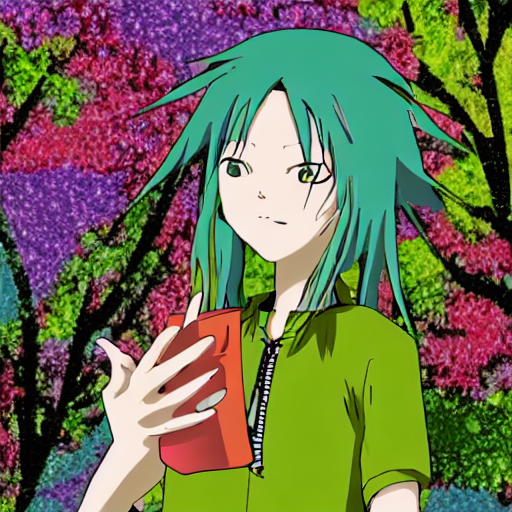

In [6]:
generation_state = None
if RUN_GENERATION_TEST:
    generation_state = run(
        'generate an anime-style character in a colorful forest',
        out=OUT_DIR,
    )
    print({
        'route': generation_state.route,
        'result_path': generation_state.result_path,
        'error': generation_state.error,
        'critique': generation_state.critique,
    })
    if generation_state.result_path and Path(generation_state.result_path).exists():
        from IPython.display import display
        from PIL import Image
        display(Image.open(generation_state.result_path))
else:
    print('Generation test skipped because RUN_PART3_GENERATION is not 1.')

In [7]:
summary = {
    'selected_rank': SELECTED_RANK,
    'adapter_dir': str(ADAPTER_DIR),
    'metrics_path': str(metrics_path) if metrics_path.exists() else None,
    'trace_count': len(list(OUT_DIR.glob('trace_*.json'))),
    'result_image_count': len(list(OUT_DIR.glob('result_*.png'))),
    'generation_result': generation_state.result_path if generation_state else None,
    'generation_error': generation_state.error if generation_state else None,
}
(OUT_DIR / 'run_summary.json').write_text(
    json.dumps(summary, indent=2),
    encoding='utf-8',
)
print(json.dumps(summary, indent=2))

{
  "selected_rank": 16,
  "adapter_dir": "C:\\Users\\saketh1\\Desktop\\lab2_solution\\part2\\outputs\\lora_rank16",
  "metrics_path": "C:\\Users\\saketh1\\Desktop\\lab2_solution\\part3\\outputs\\metrics.json",
  "trace_count": 7,
  "result_image_count": 10,
  "generation_result": "C:\\Users\\saketh1\\Desktop\\lab2_solution\\part3\\outputs\\result_46ee2d5a.png",
  "generation_error": ""
}


## Completion checklist

- `metrics.json` exists and contains `scenario_success_rate` and `red_team_attack_success_rate`.
- The selected-adapter test reports route `domain_style`.
- The selected-adapter test creates a PNG and reports an empty `error`.
- `run_summary.json` and trace JSON files are saved under `part3/outputs/`.

After reviewing the outputs, run `python report\build_report.py` from the project root and inspect the generated PDF.